In [1]:
import pandas as pd
import os
import joblib
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
from sklearn.metrics import roc_auc_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import matthews_corrcoef
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import roc_curve, auc
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as mat
import seaborn as sb

In [2]:
#Using Breast Cancer Wisconsin dataset

In [3]:
# 1. Define the 32 column names based on wdbc.names
feature_names = [
    "radius_mean", "texture_mean", "perimeter_mean", "area_mean", "smoothness_mean",
    "compactness_mean", "concavity_mean", "concave_points_mean", "symmetry_mean", "fractal_dimension_mean",
    "radius_se", "texture_se", "perimeter_se", "area_se", "smoothness_se",
    "compactness_se", "concavity_se", "concave_points_se", "symmetry_se", "fractal_dimension_se",
    "radius_worst", "texture_worst", "perimeter_worst", "area_worst", "smoothness_worst",
    "compactness_worst", "concavity_worst", "concave_points_worst", "symmetry_worst", "fractal_dimension_worst"
]

column_names = ["id", "diagnosis"] + feature_names

# 2. Read the wdbc.data file into a DataFrame
# header=None tells pandas that the file doesn't have column titles in line 1
df = pd.read_csv("wdbc.data", header=None, names=column_names)

# 3. Drop the 'id' column since it is just an identifier and has no predictive value
df = df.drop(columns=["id"])

# 4. Check the size of the dataset (Rows, Columns)
print("Shape of the dataset (instances, features + target):", df.shape)

# 5. Check class distribution (Malignant vs Benign)
print("\nDiagnosis Counts:")
print(df["diagnosis"].value_counts())

# 6. Display the first 5 rows
df.head()

Shape of the dataset (instances, features + target): (569, 31)

Diagnosis Counts:
diagnosis
B    357
M    212
Name: count, dtype: int64


,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [4]:
#Exploratory Data Analysis:

In [5]:
#null count:
total_missing_values = df.isnull().sum().sum()
print(f"Total missing values in dataset: {total_missing_values}")

#target mapping:
label = {'M': 1, 'B': 0}
df['diagnosis'] = df['diagnosis'].map(label)

#separating features and output:
X = df.drop(columns=['diagnosis'])
y = df['diagnosis']

print("\nFeature matrix (X) shape:", X.shape)
print("Target vector (y) shape:", y.shape)
print("\nClass distribution in y (1 = Malignant, 0 = Benign):")
print(y.value_counts())

Total missing values in dataset: 0

Feature matrix (X) shape: (569, 30)
Target vector (y) shape: (569,)

Class distribution in y (1 = Malignant, 0 = Benign):
diagnosis
0    357
1    212
Name: count, dtype: int64


In [6]:
#Splitting dataset:

In [7]:
# 80% training; 20% testing:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

#saving testing data into a separate CSV file:
test_data = X_test.copy()
test_data['diagnosis'] = y_test
test_data.to_csv("test_data.csv", index=False)
print("Shape of test_data.csv:", test_data.shape)

#'model' directory for saving required processing artifacts (models):
os.makedirs("model", exist_ok=True)

#Standard Scaler for transformation:
sc = StandardScaler()
X_train_scaled = sc.fit_transform(X_train)
X_test_scaled = sc.transform(X_test)

#in-memory Python object to a real file on your hard disk:
joblib.dump(sc, "model/scaler.joblib")
joblib.dump(list(X.columns), "model/feature_columns.joblib")
print("Saved scaler.joblib and feature_columns.joblib inside model/")

Shape of test_data.csv: (114, 31)
Saved scaler.joblib and feature_columns.joblib inside model/


In [8]:
#Machine Learning Models:

In [9]:
#definition for saving results:

In [10]:
# list for saving results of each model:
all_models_result = []

def evaluate_and_save_model(model_name, model, file_slug):
    # predicting class results (0 or 1):
    y_pred = model.predict(X_test_scaled)
    
    #probability prediction for AUC calculation:
    y_proba = model.predict_proba(X_test_scaled)[:, 1]
    
    #metrics calculation:
    acc = accuracy_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_proba)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    mcc = matthews_corrcoef(y_test, y_pred)
    
    #summary:
    metric_entry = {
        "ML Model Name": model_name,
        "Accuracy": round(acc, 4),
        "AUC": round(auc, 4),
        "Precision": round(prec, 4),
        "Recall": round(rec, 4),
        "F1": round(f1, 4),
        "MCC": round(mcc, 4)
    }
    all_models_result.append(metric_entry)
    
    # 5 saving model artifact:
    os.makedirs("model", exist_ok=True)
    save_path = os.path.join("model", f"{file_slug}.joblib")
    joblib.dump(model, save_path)
    
    print(f"=== {model_name} Results ===")
    for k, v in metric_entry.items():
        if k != "ML Model Name":
            print(f"{k}: {v}")
    print(f"Saved artifact to: {save_path}\n")

In [11]:
#Logistic Regression:

In [12]:
# Logistic Model initialization:
logistic_regression_model = LogisticRegression(max_iter=1000, random_state=42)

# model training using train data:
logistic_regression_model.fit(X_train_scaled, y_train)

# evaluation:
evaluate_and_save_model("Logistic Regression", logistic_regression_model, "logistic_regression")

=== Logistic Regression Results ===
Accuracy: 0.9649
AUC: 0.996
Precision: 0.975
Recall: 0.9286
F1: 0.9512
MCC: 0.9245
Saved artifact to: model\logistic_regression.joblib



In [13]:
#Decision Tree:

In [14]:
# Decision Tree Model initialization:
decision_tree_model = DecisionTreeClassifier(max_depth=4, random_state=42)

# model training using train data:
decision_tree_model.fit(X_train_scaled, y_train)

# evaluation:
evaluate_and_save_model("Decision Tree", decision_tree_model, "decision_tree")

=== Decision Tree Results ===
Accuracy: 0.9123
AUC: 0.877
Precision: 0.9444
Recall: 0.8095
F1: 0.8718
MCC: 0.8113
Saved artifact to: model\decision_tree.joblib



In [15]:
#K-Nearest Neighbour:

In [16]:
# K-Nearest Neighbour initialization:
k_nearest_neighbors_model = KNeighborsClassifier(n_neighbors=5)

#training model using train data:
k_nearest_neighbors_model.fit(X_train_scaled, y_train)

#evaluation:
evaluate_and_save_model("KNN", k_nearest_neighbors_model, "knn")

=== KNN Results ===
Accuracy: 0.9561
AUC: 0.9823
Precision: 0.9744
Recall: 0.9048
F1: 0.9383
MCC: 0.9058
Saved artifact to: model\knn.joblib



In [17]:
#Naive Bayes:

In [18]:
# Naive Bayes model initialization:
naive_bayes_model = GaussianNB()

# model training using train data:
naive_bayes_model.fit(X_train_scaled, y_train)

#evaluation:
evaluate_and_save_model("Naive Bayes", naive_bayes_model, "naive_bayes")

=== Naive Bayes Results ===
Accuracy: 0.9211
AUC: 0.9891
Precision: 0.9231
Recall: 0.8571
F1: 0.8889
MCC: 0.8292
Saved artifact to: model\naive_bayes.joblib



In [19]:
#Support Vector Machine:

In [20]:
# SVM model initialization:
support_vector_machine_model = SVC(kernel='rbf', probability=True, random_state=42)

# model training using train data:
support_vector_machine_model.fit(X_train_scaled, y_train)

# evaluate:
evaluate_and_save_model("Support Vector Machine", support_vector_machine_model, "svm")

C:\Users\Service pc\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


=== Support Vector Machine Results ===
Accuracy: 0.9737
AUC: 0.9947
Precision: 1.0
Recall: 0.9286
F1: 0.963
MCC: 0.9442
Saved artifact to: model\svm.joblib



In [21]:
#Result comparison:

In [22]:
result_data = pd.DataFrame(all_models_result)
print("=== FINAL MODEL COMPARISON TABLE ===")
result_data

=== FINAL MODEL COMPARISON TABLE ===


,ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.9649,0.9960,0.9750,0.9286,0.9512,0.9245
1,Decision Tree,0.9123,0.8770,0.9444,0.8095,0.8718,0.8113
2,KNN,0.9561,0.9823,0.9744,0.9048,0.9383,0.9058
3,Naive Bayes,0.9211,0.9891,0.9231,0.8571,0.8889,0.8292
4,Support Vector Machine,0.9737,0.9947,1.0000,0.9286,0.9630,0.9442


In [23]:
#Visualization:

In [24]:
ml_models = {
    "Logistic Regression": logistic_regression_model,
    "Decision Tree": decision_tree_model,
    "KNN": k_nearest_neighbors_model,
    "Naive Bayes": naive_bayes_model,
    "Support Vector Machine": support_vector_machine_model
}

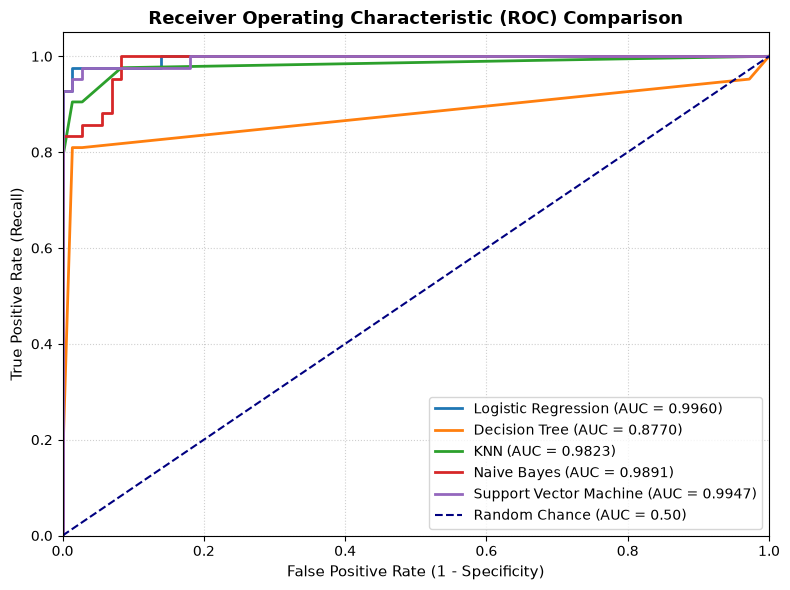

In [25]:
fig_roc, ax_roc = mat.subplots(figsize=(8, 6))

for model_name, model_obj in ml_models.items():
    probs = model_obj.predict_proba(X_test_scaled)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, probs)
    roc_auc = auc(fpr, tpr)
    ax_roc.plot(fpr, tpr, lw=2, label=f"{model_name} (AUC = {roc_auc:.4f})")

ax_roc.plot([0, 1], [0, 1], color="navy", lw=1.5, linestyle="--", label="Random Chance (AUC = 0.50)")

ax_roc.set_xlim([0.0, 1.0])
ax_roc.set_ylim([0.0, 1.05])
ax_roc.set_xlabel("False Positive Rate (1 - Specificity)", fontsize=11)
ax_roc.set_ylabel("True Positive Rate (Recall)", fontsize=11)
ax_roc.set_title("Receiver Operating Characteristic (ROC) Comparison", fontsize=13, fontweight="bold")
ax_roc.legend(loc="lower right", frameon=True)
ax_roc.grid(True, linestyle=":", alpha=0.6)

mat.tight_layout()
fig_roc.savefig("roc_curves_comparison.png", dpi=300)
mat.show()

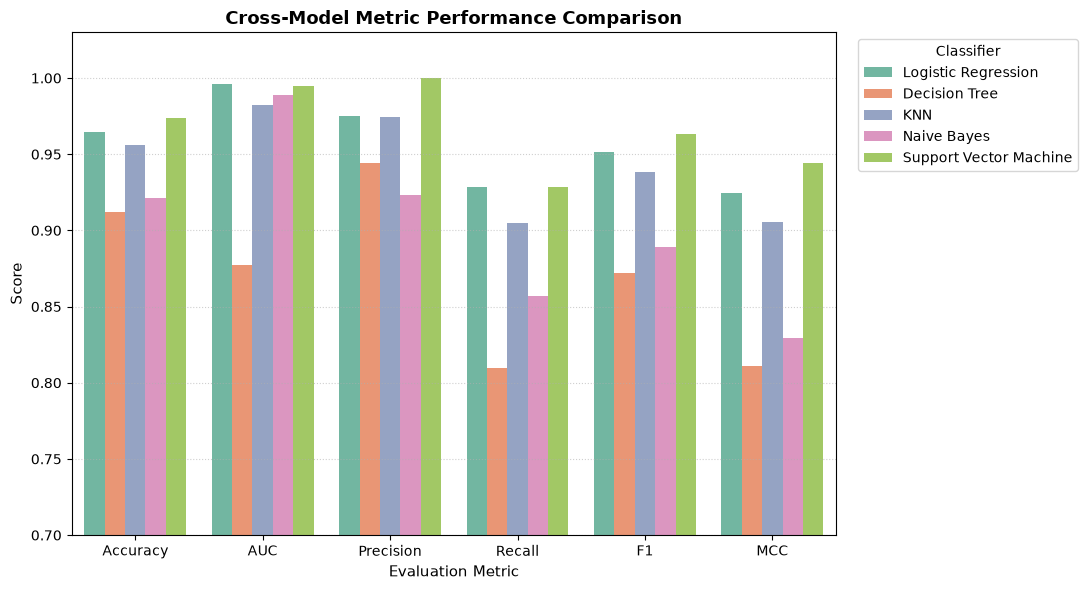

In [26]:
metrics_to_plot = ["Accuracy", "AUC", "Precision", "Recall", "F1", "MCC"]
df_melted = pd.melt(
    result_data,
    id_vars=["ML Model Name"],
    value_vars=metrics_to_plot,
    var_name="Metric",
    value_name="Score"
)
fig_bar, ax_bar = mat.subplots(figsize=(11, 6))
sb.barplot(
    data=df_melted,
    x="Metric",
    y="Score",
    hue="ML Model Name",
    palette="Set2",
    ax=ax_bar
)
ax_bar.set_ylim(0.70, 1.03)
ax_bar.set_title("Cross-Model Metric Performance Comparison", fontsize=13, fontweight="bold")
ax_bar.set_ylabel("Score", fontsize=11)
ax_bar.set_xlabel("Evaluation Metric", fontsize=11)
ax_bar.legend(title="Classifier", bbox_to_anchor=(1.02, 1), loc="upper left")
ax_bar.grid(axis="y", linestyle=":", alpha=0.6)

mat.tight_layout()
fig_bar.savefig("metrics_comparison_barchart.png", dpi=300)
mat.show()

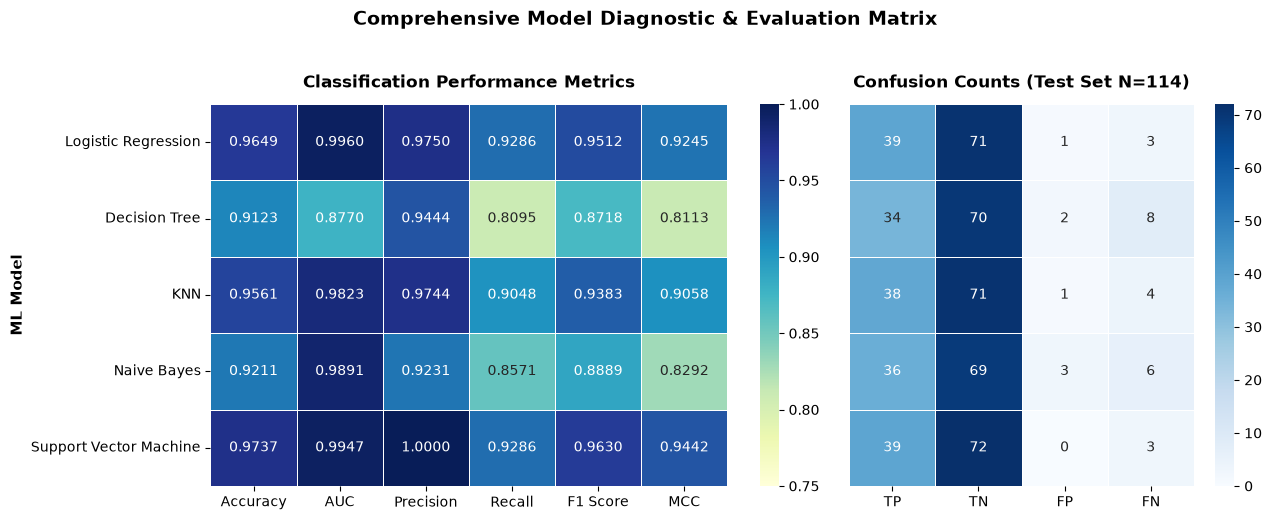

In [27]:
matrix_records = []

for model_name, model_obj in ml_models.items():
    y_pred = model_obj.predict(X_test_scaled)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    
    metric_row = next(item for item in all_models_result if item["ML Model Name"] == model_name)
    
    matrix_records.append({
        "Model": model_name,
        "Accuracy": metric_row["Accuracy"],
        "AUC": metric_row["AUC"],
        "Precision": metric_row["Precision"],
        "Recall": metric_row["Recall"],
        "F1 Score": metric_row["F1"],
        "MCC": metric_row["MCC"],
        "TP": int(tp),
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn)
    })

df_matrix = pd.DataFrame(matrix_records).set_index("Model")

rate_cols = ["Accuracy", "AUC", "Precision", "Recall", "F1 Score", "MCC"]
count_cols = ["TP", "TN", "FP", "FN"]

df_rates = df_matrix[rate_cols]
df_counts = df_matrix[count_cols]

fig_matrix, (ax1, ax2) = mat.subplots(
    nrows=1, 
    ncols=2, 
    figsize=(13, 5), 
    gridspec_kw={'width_ratios': [6, 4]}
)

sb.heatmap(
    df_rates, 
    annot=True, 
    fmt=".4f", 
    cmap="YlGnBu", 
    vmin=0.75, 
    vmax=1.0, 
    cbar=True, 
    ax=ax1,
    linewidths=0.5
)
ax1.set_title("Classification Performance Metrics", fontsize=12, fontweight="bold", pad=12)
ax1.set_ylabel("ML Model", fontsize=11, fontweight="bold")

sb.heatmap(
    df_counts, 
    annot=True, 
    fmt="d", 
    cmap="Blues", 
    cbar=True, 
    ax=ax2,
    linewidths=0.5
)
ax2.set_title("Confusion Counts (Test Set N=114)", fontsize=12, fontweight="bold", pad=12)
ax2.set_ylabel("")
ax2.set_yticks([])

mat.suptitle("Comprehensive Model Diagnostic & Evaluation Matrix", fontsize=14, fontweight="bold", y=1.03)
mat.tight_layout()

fig_matrix.savefig("model_diagnostic_matrix.png", dpi=300, bbox_inches="tight")
mat.show()